In [1]:
# python -m venv desired_venv_name
# cd H:\CODING_PROJECTS\project_3d_perception_pipeline
# desired_venv_name\Scripts\activate

# python -m venv depth_est_venv
# cd H:\CODING_PROJECTS\project_3d_perception_pipeline
# depth_est_venv\Scripts\activate
# deactivate
#if can't find kernel, find the manual path of the folder/venv folder/Python.exe

#### Python 3.12 Specific Version - Create Virtual Environment for Open3D
# cd H:\CODING_PROJECTS\project_3d_perception_pipeline
# python312_portable\python.exe -m venv depth_est_venv_312
# depth_est_venv_312\Scripts\Activate
# deactivate
#if can't find kernel, find the manual path of the folder/venv folder/Python.exe

# 3D Perception Depth Estimation Pipeline / Notes and Learnings



## Phase 1. Inference & Depth Pipeline

Set up Depth Anything v2 PyTorch checkpoint; write pre-processing pipeline for RGB frames; run forward-pass inference to generate dense depth maps.

- Tools Used: Python, PyTorch, OpenCV, NumPy

### Primary Reference: Depth Anything V2 Codebase

- https://depth-anything-v2.github.io/
- Depth Anything V2 Paper
- https://github.com/DepthAnything/Depth-Anything-V2
- Live Simulation: https://huggingface.co/spaces/depth-anything/Depth-Anything-V2

### References for Tutorials:

- https://visionbrick.com/depth-anything-v2-generating-depth-maps-from-rgb-images/
- https://www.youtube.com/watch?v=1Lt4p-cf_6Y
- https://amanjaglan.medium.com/generating-3d-images-and-point-clouds-with-python-open3d-and-glpn-for-depth-estimation-a0a484d77570

### References for Supplementary Libraries:

- Color Maps for Matplotlib: https://matplotlib.org/stable/users/explain/colors/colormaps.html


**Depth Anything V2:** Produces a relative depth map from a single RGB image (**monocular depth estimation**).

1. Create a proper environnment for depth estimation
2. Generate depth map using Depth Anything V2 on RGB images

#### How Depth Anything V2 works?
- 3 Main stages of training method of the Depth Anything model:
1. Training teacher model on synthetic dataset
2. Pseudo-Labeling using teacher model on real-world images
3. Student model training using real-world annotated dataset

Real-world labeled datasets are not that clear, there can be wrong annotations, missing objects, or poor annotations. Even the most popular datasets (KITTI) are not perfectly clear. So, the authors of Depth Anything V2 decided to use synthetic datasets for training. Synthetic datasets offer pixel-perfect, precise depth labels. They are simply generated by computers, not by human annotators.

But of course, if only the synthetic dataset were used, it wouldn’t be practical for real-world scenarios. So, by using the teacher model, from real-world images (62 million unlabeled real images), a new dataset is created. Basically, the teacher model is used for annotation.

Finally, the student model is trained on this new dataset annotated by the teacher model. This allows the model to learn about real-world scenarios and get more realistic results. It is worth mentioning that the student model is only trained on real-world annotated images, and the authors state that removing the synthetic images entirely gave better results.

## 1. Pre-Installation Packages and Git LFS Uploads (if necessary)

In [2]:
! python -m pip install opencv-python
#! python -m pip install numpy
! python -m pip install matplotlib
! python -m pip install open3d

! pip install "numpy<2.0.0" 
! pip install tqdm
! pip install torch==2.5.1 torchvision==0.20.1 --index-url https://download.pytorch.org/whl/cu121

'''tqdm = popular Python library used to add a fast extensible progress bar to loops
When processing images or videos for depth estimation, running deep learning models can take time. 
Instead of looking at a frozen terminal, tqdm wraps around your data loops to show a live progress visual
'''

'''
! python -m pip cache purge
'''
#optional packages to clear messages or speed up model inference using NVIDIA GPU
#! python -m pip install xformers
#! python -m pip install xformers==0.0.26.dev767
#! python -m pip uninstall xformers #to remove if running error

# git lfs track "*.pyd" #Designate .blank files to be managed by LFS
# git lfs track "*.pyc" #Designate .blank files to be managed by LFS
# git add .gitattributes

'\n! python -m pip cache purge\n'

In [3]:
# Import required packages

# PHASE 1: Depth Estimation and future
import cv2 # Import the OpenCV library
import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline

import glob
import sys
import os

print(f"Torch Version: {torch.__version__} (CUDA Available: {torch.cuda.is_available()})")
print(f"Torchvision Version: {torch.__version__}")

# PHASE 2: Generate Point Cloud with Open3D
import open3d as o3d

print(f"Open3D Version: {o3d.__version__}")


Torch Version: 2.5.1+cu121 (CUDA Available: False)
Torchvision Version: 2.5.1+cu121
Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Open3D Version: 0.19.0


## 2. Clone the Depth Anything V2 Repo

HOWTO: Cloning the online repo from elsewhere and keeping own project's code separate:
1. clone the online repository into your main Developer-Projects folder.
2. In your own project's code, you use relative paths (e.g., import tool from '../online-library-repo') or package manager links to use it.

Pros:Your main project stays small and clean. You can easily run git pull inside the online repo to get updates without messing up your own code.Cons: 
If you move your project folder to a different computer, you have to remember to clone the online repo again and put it in the exact same spot.

### Alternate Method of cloning repo with relative paths using os.path:

# Get the folder where this notebook is running, move up one level, and find the repo
base_dir = os.path.dirname(os.getcwd())
cloned_repo_path = os.path.join(base_dir, "CODING_GITHUB", "Depth-Anything-V2")

sys.path.append(cloned_repo_path)

### Step 1: Clone the Repo

In [4]:
#Git clone the Depth Anything V2 repo to the main GitHub Repo
'''Option 1: Cloning Directly:'''
# git clone https://github.com/DepthAnything/Depth-Anything-V2 #If direct clone

'''Option 2: Cloning from a separate folder location:'''
# 1. Store cloned file path: 
#cloned_repo_path = os.path.abspath("../online-library-repo") #moves up one folder level, and steps into cloned repo
#cloned_repo_path = os.path.abspath("../CODING_GITHUB/Depth-Anything-V2") #Moves up one level, goes down following folder paths
# Direct literal path to the parent folder of depth_anything_v2
cloned_repo_path = r"H:\CODING_GITHUB\Depth-Anything-V2"

sys.path.append(cloned_repo_path)

### Step 2: Install Requirements from the Correct Path

In [5]:
#Step 1: Install Requirements from the Correct Path
# When installing the dependencies, modify the cd command to point to the actual folder path where you cloned the repository:bash# Navigate to your actual clone directory, wherever it lives on your desktop
#cd "C:\path\to\your\other\folder\Depth-Anything-V2"
#cd H:\CODING_GITHUB\Depth-Anything-V2

# Install the required packages
#python -m pip install -r requirements.txt

### Step 3: Load the module from the cloned repo into current project script cleanly

If using VS Code / Cursor:
Open your workspace settings (Press Ctrl + , on Windows).

Search for Extra Paths.

Under Python > Analysis: Extra Paths, click Add Item.

Paste the literal path to your repository: H:\CODING_GITHUB\Depth-Anything-V2

Save and restart your editor window.The red line will disappear instantly because the background analyzer now knows exactly where the module lives.

In [6]:
#ADD THIS: Point Python to the exact folder where the repo is cloned
# (Make sure this points to the root folder containing the 'depth_anything_v2' folder)
# sys.path.append("C:/path/to/your/other/folder/Depth-Anything-V2")
#In your current project script, add sys.path.append at the very top. 
# This dynamically links your current script to the external repository at runtime:
#module_path = f'../CODING_GITHUB/Depth-Anything-V2' #Moves up one level, goes down following folder paths
sys.path.append(cloned_repo_path)
#Python needs sys.path to target the folder containing depth_anything_v2. By 
# targeting Depth-Anything-V2, your statement from depth_anything_v2.dpt can successfully 
# resolve down into the subfolder and read dpt.py.


# Because of the path appended, Python can now find and load the module cleanly
# 2. Import python modules from cloned repo to access in this project code
#import name_of_python_file_inside_cloned_repo
from depth_anything_v2.dpt import DepthAnythingV2

'''In case of response: xFormers not available:

xFormers not available: This is a standard notification from PyTorch/HuggingFace libraries. 
xFormers is an optional optimization library used to speed up image processing on specific 
NVIDIA graphics cards.Do you need to fix it?: No. The Depth-Anything-V2 code has built-in 
fallbacks. Because xFormers isn't installed, it will automatically switch to standard 
PyTorch attention algorithms. The model will run completely fine without it.

Pip install xformers to remove'''

xFormers not available
xFormers not available


"In case of response: xFormers not available:\n\nxFormers not available: This is a standard notification from PyTorch/HuggingFace libraries. \nxFormers is an optional optimization library used to speed up image processing on specific \nNVIDIA graphics cards.Do you need to fix it?: No. The Depth-Anything-V2 code has built-in \nfallbacks. Because xFormers isn't installed, it will automatically switch to standard \nPyTorch attention algorithms. The model will run completely fine without it.\n\nPip install xformers to remove"

## Part 1: Generate Depth Map

### Step 4: Configure device for project - Load Model

In [7]:
print(os.getcwd())


# 1. Force PyTorch math contexts to only use basic CPU execution
with torch.backends.cuda.sdp_kernel(enable_flash=False, enable_math=True, enable_mem_efficient=False):

    device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
    map_location = 'cpu' #Chosen cuda or mps or cpu

    #Load models
    #Configure the models downloaded into checkpoints folder
    model_configs = {
        'vits': {'encoder': 'vits', 'features': 64, 'out_channels': [48, 96, 192, 384]},
        'vitb': {'encoder': 'vitb', 'features': 128, 'out_channels': [96, 192, 384, 768]},
        'vitl': {'encoder': 'vitl', 'features': 256, 'out_channels': [256, 512, 1024, 1024]},
        'vitg': {'encoder': 'vitg', 'features': 384, 'out_channels': [1536, 1536, 1536, 1536]}
        }

    #if a different model is used, change here in encoder variable
    chosen_model = "vitl" #Below code lines use the encoder model chosen here
    encoder = model_configs[chosen_model]['encoder']


    model = DepthAnythingV2(encoder) #Initialize model
    model_relative_path = f'../../CODING_GITHUB/Depth-Anything-V2/checkpoints/depth_anything_v2_{encoder}.pth'

    #Load path of the model installed in checkpoints folder
    model.load_state_dict(torch.load(model_relative_path, map_location = map_location))

    #Move model to device and set to evaluation model
    #model = model.to(device).eval() #for version when GPU may be possible to be used
    model = model.to('cpu').eval()


h:\CODING_PROJECTS\project_3d_perception_pipeline\python_312_portable\Lib\contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)


h:\CODING_PROJECTS\project_3d_perception_pipeline


C:\Users\kathy\AppData\Local\Temp\ipykernel_3164\290095317.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_relative_path, map_loc

### Step 5: Read Input image and run (Relative) Depth Estimation Model - Static JPG Image Version

Note: Shape of the depth_map variable is exactly the same as the image size, because there is one value for each pixel. Since the output is a relative depth map, values don’t correspond to any real length. Actually, values are inversely related to distance. Smaller values mean that a pixel is far away from a bigger-valued pixel.

Later: After generating relative depth map, you can try to measure real length by using static objects. Like avg person length, or any other object that exists in your image. 

Shape: (1065, 1600)
Data Type: float32
Value Range: Min to Max [Min 0.0000, Max 412.5233]
Mean Value: 112.8575
Std Deviation: 132.9244


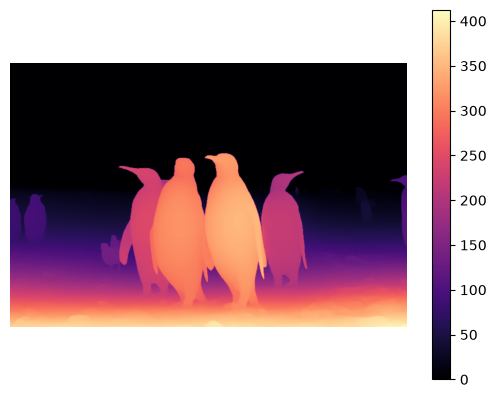

In [8]:
#List path to image from directory
img_name ='penguins'
#img_name = 'mountains'
#img_name = 'hiker'

#Read in image
img_path = f'input_images/{img_name}.jpg' #relative path uses f'//', abs path uses r'\\'

if not os.path.exists(img_path): #Check that file physically exists
    print(f"Error: The file path does not exist -> {os.path.abspath(img_path)}")
else:
    image = cv2.imread(img_path) #Read in image file at the img_path name

#Compute depth map
depth_map = model.infer_image(image)

# Assume 'depth_map' is your raw float32/float64 depth array
# Normalize depth data to the 0-65535 range
depth_min = depth_map.min()
depth_max = depth_map.max()

# Avoid division by zero if the image is flat
if depth_max > depth_min:
    depth_normalized = (depth_map - depth_min) / (depth_max - depth_min)
else:
    depth_normalized = np.zeros_like(depth_map)

# Convert to 16-bit unsigned integer
depth_16bit = (depth_normalized * 65535).astype(np.uint16)

""" ### Alternate version of normalizing the depth map image:
depth_normalized = cv2.normalize(depth_map, None, 0, 255, cv2.NORM_MINMAX)
depth_scaled = depth_normalized.astype(np.uint16)

"""

""" ## Coloring the depth map image that is saved to directory:
depth_colored = cv2.applyColorMap(depth_scaled, cv2.COLORMAP_INFERNO)
cv2.imwrite("depth_map_colored.jpg", depth_colorec)

"""

#HOWTO save depth_map variable directly, as it is an image: cv2.imwrite()
depth_map_img = cv2.imwrite(f"depth_map_16bit_{img_name}.png", depth_map)

#HOWTO display depth_map with matplotlib
plot_color_gradients = {
    'Perceptually Uniform Sequential':['viridis', 'plasma', 'inferno', 'magma', 'cividis'], 
    'Sequential':['Greys', 'Purples', 'Blues', 'Greens', 'Oranges', 'Reds','YlOrBr', 
                  'YlOrRd', 'OrRd', 'PuRd', 'RdPu', 'BuPu', 'GnBu', 'PuBu', 'YlGnBu', 
                  'PuBuGn', 'BuGn', 'YlGn'], 
    'Sequential (2)':['gray', 'bone', 'pink', 'spring', 'summer', 'autumn','winter', 
                      'cool', 'Wistia', 'hot', 'afmhot', 'gist_heat','copper'],
    'Diverging': ['PiYG', 'PRGn', 'BrBG', 'PuOr', 'RdGy', 'RdBu', 'RdYlBu',
                      'RdYlGn', 'Spectral', 'coolwarm', 'bwr', 'seismic',
                      'berlin', 'managua', 'vanimo'],
    'Cyclic': ['twilight', 'twilight_shifted', 'hsv'],
    'Qualitative': ['Pastel1', 'Pastel2', 'Paired', 'Accent', 'okabe_ito',
                      'Dark2', 'Set1', 'Set2', 'Set3', 'tab10', 'tab20',
                      'tab20b', 'tab20c']
                      }
plt.imshow(depth_map, cmap = "magma")
plt.colorbar()
plt.axis('off')

#Print different attributes of the produced depth map created from model
print(f'Shape: {depth_map.shape}')
print(f'Data Type: {depth_map.dtype}')
print(f'Value Range: Min to Max [Min {depth_map.min():.4f}, Max {depth_map.max():.4f}]')
print(f'Mean Value: {depth_map.mean():.4f}')
print(f'Std Deviation: {depth_map.std():.4f}')

In [9]:
## For many images in a loop - Alternate Version

'''
#List path to image from directory
img_names = ['penguins', 'mountains', 'hiker']
depth_maps = {}

for element in img_names: #Loop through all elements in img_names array
    #Read in image
    img_path = f'input_images/{element}.jpg' #relative path uses f'//', abs path uses r'\\'

    if not os.path.exists(img_path): #Check that file physically exists
        print(f"Error: The file path does not exist -> {os.path.abspath(img_path)}")
    else:
        image = cv2.imread(img_path) #Read in image file at the img_path name

    #Compute depth map
    depth_map = model.infer_image(image)

    # Assume 'depth_map' is your raw float32/float64 depth array
    # Normalize depth data to the 0-65535 range
    depth_min = depth_map.min()
    depth_max = depth_map.max()

    # Avoid division by zero if the image is flat
    if depth_max > depth_min:
        depth_normalized = (depth_map - depth_min) / (depth_max - depth_min)
    else:
        depth_normalized = np.zeros_like(depth_map)

    # Convert to 16-bit unsigned integer
    depth_16bit = (depth_normalized * 65535).astype(np.uint16)

    #HOWTO save depth_map variable directly, as it is an image: cv2.imwrite()
    depth_maps[element] = cv2.imwrite(f"depth_map_16bit_{element}.png", depth_16bit)

    #HOWTO display depth_map with matplotlib
    plt.imshow(depth_map, cmap = "magma")
    plt.colorbar()
    plt.axis('off')

    #Print different attributes of the produced depth map created from model
    print(f'Shape: {depth_map.shape}')
    print(f'Data Type: {depth_map.dtype}')
    print(f'Value Range: Min to Max [Min {depth_map.min():.4f}, Max {depth_map.max():.4f}]')
    print(f'Mean Value: {depth_map.mean():.4f}')
    print(f'Std Deviation: {depth_map.std():.4f}')

'''

'\n#List path to image from directory\nimg_names = [\'penguins\', \'mountains\', \'hiker\']\ndepth_maps = {}\n\nfor element in img_names: #Loop through all elements in img_names array\n    #Read in image\n    img_path = f\'input_images/{element}.jpg\' #relative path uses f\'//\', abs path uses r\'\\\'\n\n    if not os.path.exists(img_path): #Check that file physically exists\n        print(f"Error: The file path does not exist -> {os.path.abspath(img_path)}")\n    else:\n        image = cv2.imread(img_path) #Read in image file at the img_path name\n\n    #Compute depth map\n    depth_map = model.infer_image(image)\n\n    # Assume \'depth_map\' is your raw float32/float64 depth array\n    # Normalize depth data to the 0-65535 range\n    depth_min = depth_map.min()\n    depth_max = depth_map.max()\n\n    # Avoid division by zero if the image is flat\n    if depth_max > depth_min:\n        depth_normalized = (depth_map - depth_min) / (depth_max - depth_min)\n    else:\n        depth_norma

### Step 5: View Depth Maps Side by Side with Original Image

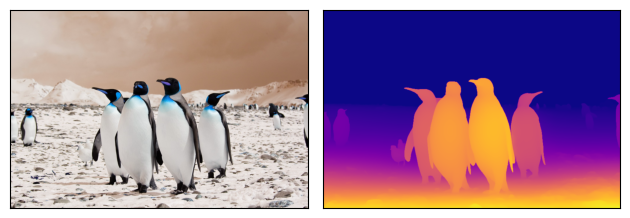

In [10]:
#Setup up graphs
fig, ax = plt.subplots(1, 2)
ax[0].imshow(image)
ax[0].tick_params(left = False, bottom = False, labelleft = False, labelbottom = False)
ax[1].imshow(depth_map, cmap = 'plasma')
ax[1].tick_params(left = False, bottom = False, labelleft = False, labelbottom = False)
plt.tight_layout()
plt.pause(5)

#Comparing original image in variable 'image' vs manipulated image 'depth_map'

### Post Process Depth Map Further
- Add padding
- Crop images to remove border effect

## Phase 2: Point Cloud Maps

Generating a 3D point cloud froma  3D estimation using the Depth Anything V2 model for depth estimation and the Open3D library for point cloud creation and visualization. 

Purpose: Provides an exciting way to explore 3D reconstructions from simple 2D images

https://amanjaglan.medium.com/generating-3d-images-and-point-clouds-with-python-open3d-and-glpn-for-depth-estimation-a0a484d77570

## Part 2: Generate Point Cloud using Open3D

- **Point Cloud:** Created by library Open3D. A large set of data pts plotted in 3D dimensional coordinate system
    - Each dot has exact X, Y, and Z coordinates that represent an external sruface or physical space
    - Together, millions of these dots form a detailed 3D digital shape of an object, building or landscape
    - NOTE: Can create point clouds from multiple different kinds of image formats


- **Camera Intrinsic Estimation:** Estimating the camera's internal parameters (that sit inside the camera)
    - describe to humans how a point from the 3D world is mapped onto the 2D image plane
    - *Goal of Calibration:* That we know for every pixel the precision direction vector from the origin of the camera so that the production center of our camera into the 3D world
    - 

- **open3d.geometry.Image:** Image class - that stores image with customizable width, height, num of channels, and bytes per channel
    - Resource: https://www.open3d.org/html/python_api/open3d.geometry.Image.html

- **rgbd_image = o3d.geometry.RGBDImage.create_from_color_and_depth():** Creates a RGBDImage object from color and the depth_image file
    - Parameters: 
        - color (open3d.geometry.Image) – The color image.
        - depth (open3d.geometry.Image) – The depth image.
        - depth_scale (float, optional, default=1000.0) – The ratio to scale depth values. The depth values will first be scaled and then truncated.
        - depth_trunc (float, optional, default=3.0) – Depth values larger than depth_trunc gets truncated to 0. The depth values will first be scaled and then truncated.
        - convert_rgb_to_intensity (bool, optional, default=True) – Whether to convert RGB image to intensity image.
    - Resource: https://www.open3d.org/docs/0.7.0/python_api/open3d.geometry.create_rgbd_image_from_color_and_depth.html

- **open3d.geometry.create_point_cloud_from_rgbd_image(image, intrinsic, extrinsic=(with default value)):** Factory function that creates a point cloud from an RGB-D image and a camera
    - Given values: depth_value d at (u, v)
    - corresponding 3d point is:
        -  z = d / depth_scale
        -  x = (u - cx) * z / fx
        -  y = (v - cy) * z / fy
    - Parameters
        - image (open3d.geometry.RGBDImage)
        - intrinsic (open3d.camera.PinholeCameraIntrinsic)
        - extrinsic (numpy.ndarray[float64[4, 4]], optional) – array([[1., 0., 0., 0.], [0., 1., 0., 0.], [0., 0., 1., 0.], [0., 0., 0., 1.]])
    - Returns:
        - open3d.geometry.PointCloud



    - Resource: https://www.open3d.org/docs/0.6.0/python_api/open3d.geometry.create_point_cloud_from_rgbd_image.html


### Step 1: Define functions for: defining camera intrinsic parameters and point cloud creation

In [24]:

#1. Define function to define camera's intrinsic parameters
def define_camera_intrinsic_parameters(depth_image):
    """
    Set intrinsic parameters of the camera used to capture the image
    
    """
    fx = 1000 # Focal Length in the x axis
    fy = 1000 # Focal Length in the y axis
    cx = depth_map.shape[1] / 2 # Principal point in the x axis
    cy = depth_map.shape[0] / 2 # Principal point in the y axis

    #INITIALIZE PINHOLE Camera Intrinsic parameters
    intrinsic = o3d.camera.PinholeCameraIntrinsic(
        width = depth_map.shape[1],
        height = depth_map.shape[0],
        fx = fx,
        fy = fy, 
        cx = cx, 
        cy = cy
        )

    return intrinsic

#2. Define function to create a point cloud from the depth image
def create_point_cloud_from_depth_img(depth_image, intrinsic, scale = 1.0):
    """
    Create a point cloud from a depth image using Open3D.
    
    Parameters:
        - depth_image = dumpy array containing the depth image
        - intrinsic = an Open3D camera intrinsic object
        - scale = Scaling factor to adjust the depth values

    Returns:
        - A point cloud object
    
    """
    #depth_image = depth image file that was created from depth estimate map earlier
    #intrinsic = 
    #scale = #desired scale from 0 - 1.0 equal exact scale

    #Pull height and width dimensions from current depth_image.scale
    height, width = depth_image.shape
    #Pull depth image as an Open3D geometry object, with image file divided by scale, and in np.float32 type
    depth_image = o3d.geometry.Image((depth_image / scale).astype(np.float32)) 
    #Create color image as a Open3D geometry color image object as an 8bit integer
    color_image = o3d.geometry.Image(np.zeros((height, width, 3), dtype = np.uint8))
    rgbd_image = o3d.geometry.RGBDImage.create_from_color_and_depth(
        color = color_image,
        depth = depth_image,
        convert_rgb_to_intensity = False  #Function to make RGBDImage from color and depth image
        )
    
    #Create point cloud from the RGB Depth Image
    pcd = o3d.geometry.PointCloud.create_from_rgbd_image(
        image = rgbd_image, 
        intrinsic = intrinsic,
        )

    return pcd

#1. Generate the camera intrinsic parameters from depth image
intrinsic = define_camera_intrinsic_parameters(depth_map)


## Part 3: Basic Usage of Point Cloud

### Step 1: Reading a point cloud and visualizing it

https://www.open3d.org/docs/release/tutorial/geometry/pointcloud.html

- read_point_cloud reads a point cloud from a file. It tries to decode the file based on the extension name. For a list of supported file types, refer to File IO.

- draw_geometries visualizes the point cloud. Use a mouse/trackpad to see the geometry from different view points.

- It looks like a dense surface, but it is actually a point cloud rendered as surfels. The GUI supports various keyboard functions. For instance, the - key reduces the size of the points (surfels).

- surfels = the points that make up the point cloud

In [26]:
'''
#### Alternate Version: Create and visualize point cloud object for array of image files
#For each element in depth_map (array of element files):
for depth_img in depth_maps:
    intrinsic = define_camera_intrinsic_parameters(depth_img)
    pcd = create_point_cloud_from_depth_img(depth_img, intrinsic, scale = 1.0)
'''

#2. Generate the point cloud from the depth image
pcd = create_point_cloud_from_depth_img(depth_map, intrinsic, scale = 1.0)

#. Visualize the point cloud
o3d.visualization.draw_geometries([pcd])

# Save the point cloud to a file
o3d.io.write_point_cloud("depth_map_point_cloud.ply", pcd)

#open the saved pcd file to load and read
pcd_file = o3d.io.read_point_cloud("depth_map_point_cloud.ply")
#pcd = o3d.io.read_point_cloud(ply_point_cloud.path)

print("Load a ply point cloud, print it, and render it")
#Visualize the point cloud
o3d.visualization.draw_geometries([pcd_file])
print(np.asarray(pcd_file.points))

o3d.visualization.draw_geometries([pcd_file],
                                  zoom=0.3412,
                                  front=[0.4257, -0.2125, -0.8795],
                                  lookat=[2.6172, 2.0475, 1.532],
                                  up=[-0.0694, -0.9768, 0.2024])


Load a ply point cloud, print it, and render it
[[ 0.00123559 -0.00431169  0.02574142]
 [ 0.00373648 -0.01277265  0.07625465]
 [ 0.00527003 -0.01765461  0.10540067]
 ...
 [ 0.32695334  0.21803727  0.41023004]
 [ 0.32786685  0.21837247  0.41086072]
 [ 0.3287817   0.21870772  0.41149148]]


### Voxel Downsampling

**Voxel**: AKA Volumetric Pixel. 3D Unit of graphic info. Acts as a standard flat pixel on a screen, but adds depth to form a small cube or point in a 3D grid
- Where Voxels Are Used
    Video Games: Games like Minecraft use voxel grids to build destructible 3D worlds where players can dig and shape terrain freely.
    Medical Scans: Medical tools like MRI and CT machines use voxels to map out layers of internal body tissue and volume.
    Scientific Modeling: Scientists use them in computer simulations to represent data like weather patterns, ocean currents, or underground earth layers.
- Voxels vs. Pixels and Polygons
    - Pixels: 2D picture elements on flat screens with width and height.
    - Voxels: 3D volume elements with width, height, and depth.
    - Polygons: Flat shapes (like triangles) used in standard 3D graphics. While polygons outline the surface of an object, voxels fill the entire inside volume like tiny building blocks.

**Voxel Downsampling** = A technique using a regular voxel grid to create a uniformly downsampled point cloud from an input point cloud.
    - Often used as a preprocessing step for many point cloud processing steps
    - Algorithm Steps:
        1. Points are bucketed into voxels
        2. Each occupied voxel generates exactly one point by AVERAGING all points inside

In [25]:
print("Downsample the point cloud with a voxel of 0.05")
voxel_val = 0.05

#Create downsampled pcd object with voxel_downsample() function
downpcd = pcd_file.voxel_down_sample(voxel_size = voxel_val)
o3d.visualization.draw_geometries([downpcd], 
                                  zoom=0.3412,
                                  front=[0.4257, -0.2125, -0.8795],
                                  lookat=[2.6172, 2.0475, 1.532],
                                  up=[-0.0694, -0.9768, 0.2024])



Downsample the point cloud with a voxel of 0.05
